# Day 087 | Liquefaction Susceptibility Mapping (DL)

**Author:** Ripon Chandra Malo

## Capstone Project: Deep Learning for Spatial Liquefaction Susceptibility

Liquefaction is a devastating earthquake-induced ground failure where saturated, loose, granular soils lose strength and behave like a liquid. Susceptibility mapping integrates geological, geotechnical, and seismological data to classify areas by risk level.

In this project, we build a deep learning classifier for multi-class liquefaction susceptibility mapping using spatial and geotechnical features.

**Objectives:**
- Generate synthetic spatial dataset with geotechnical features (300 rows)
- Build a deep neural network for multi-class classification (Low / Moderate / High / Very High)
- Evaluate with confusion matrix, classification report, and ROC curves
- Create spatial susceptibility maps

In [1]:
# ───── Part 1: Imports and Setup ─────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_curve, auc)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
print('All libraries loaded successfully.')

All libraries loaded successfully.


## Part 2: Synthetic Spatial Data Generation

We generate a dataset that simulates a region with varying liquefaction susceptibility. Key factors include:
- **Groundwater depth** -- shallow water tables increase susceptibility
- **SPT-N values** -- loose soils (low N) are more susceptible
- **Soil type / fines content** -- clean sands are most susceptible
- **Peak Ground Acceleration (PGA)** -- higher seismic demand increases risk
- **Distance to river** -- alluvial deposits near rivers are more susceptible
- **Elevation** -- low-lying areas tend to have higher water tables

In [2]:
# ───── Part 2: Generate Synthetic Spatial Liquefaction Dataset ─────
n_samples = 300

# Spatial coordinates (km) - simulating a 20x20 km region
x_coord = np.random.uniform(0, 20, n_samples)
y_coord = np.random.uniform(0, 20, n_samples)

# Distance to nearest river (km) - rivers at y ~ 5 and y ~ 15
dist_river = np.minimum(np.abs(y_coord - 5), np.abs(y_coord - 15))
dist_river += np.random.normal(0, 0.3, n_samples)
dist_river = np.clip(dist_river, 0.1, 10)

# Elevation (m) - lower near rivers
elevation = 20 + 3 * dist_river + np.random.normal(0, 2, n_samples)
elevation = np.clip(elevation, 5, 50)

# Groundwater depth (m) - shallower near rivers
gwt_depth = 0.5 + 0.8 * dist_river + np.random.exponential(1.0, n_samples)
gwt_depth = np.clip(gwt_depth, 0.3, 15)

# SPT-N values - lower near rivers (alluvial deposits)
spt_n = 5 + 2.5 * dist_river + np.random.normal(0, 5, n_samples)
spt_n = np.clip(spt_n, 1, 50).astype(int)

# Fines content (%) - varies spatially
fines = 15 + 10 * np.sin(x_coord / 3) + np.random.normal(0, 10, n_samples)
fines = np.clip(fines, 0, 80)

# PGA (g) - varies across region (seismic microzonation)
pga = 0.15 + 0.1 * np.sin(x_coord / 5) + 0.05 * np.cos(y_coord / 4) + np.random.normal(0, 0.03, n_samples)
pga = np.clip(pga, 0.05, 0.5)

# Liquefaction Potential Index (LPI) - composite score
lpi = (0.3 * (50 - spt_n) / 50 +
       0.25 * (15 - gwt_depth) / 15 +
       0.2 * pga / 0.5 +
       0.15 * (1 - fines / 80) +
       0.1 * (1 - dist_river / 10))
lpi = lpi + np.random.normal(0, 0.05, n_samples)

# Classify susceptibility
# Thresholds at LPI percentiles (25/55/80%) so every class is represented
t_low, t_mod, t_high = np.quantile(lpi, [0.25, 0.55, 0.80])
susceptibility = np.where(lpi < t_low, 0,         # Low
                 np.where(lpi < t_mod, 1,          # Moderate
                 np.where(lpi < t_high, 2, 3)))    # High / Very High

susc_labels = {0: 'Low', 1: 'Moderate', 2: 'High', 3: 'Very High'}

df = pd.DataFrame({
    'x_km': np.round(x_coord, 3),
    'y_km': np.round(y_coord, 3),
    'elevation_m': np.round(elevation, 1),
    'gwt_depth_m': np.round(gwt_depth, 2),
    'spt_n': spt_n,
    'fines_pct': np.round(fines, 1),
    'pga_g': np.round(pga, 3),
    'dist_river_km': np.round(dist_river, 2),
    'susceptibility': susceptibility
})

df.to_csv('liquefaction_spatial_data.csv', index=False)
print(f'Dataset shape: {df.shape}')
print(f'\nClass distribution:')
for cls, label in susc_labels.items():
    count = (df['susceptibility'] == cls).sum()
    print(f'  {label}: {count} ({100*count/len(df):.1f}%)')
df.head()

Dataset shape: (300, 9)

Class distribution:
  Low: 75 (25.0%)
  Moderate: 90 (30.0%)
  High: 75 (25.0%)
  Very High: 60 (20.0%)


,x_km,y_km,elevation_m,gwt_depth_m,spt_n,fines_pct,pga_g,dist_river_km,susceptibility
0,7.491,1.034,29.5,3.74,14,0.0,0.295,3.81,2
1,19.014,10.627,37.7,4.08,14,5.5,0.050,4.14,0
2,14.640,10.813,33.5,7.38,19,11.3,0.118,4.16,0
3,11.973,12.749,26.2,2.25,8,28.1,0.216,1.94,2
4,3.120,14.522,19.2,2.68,7,23.8,0.181,0.31,2


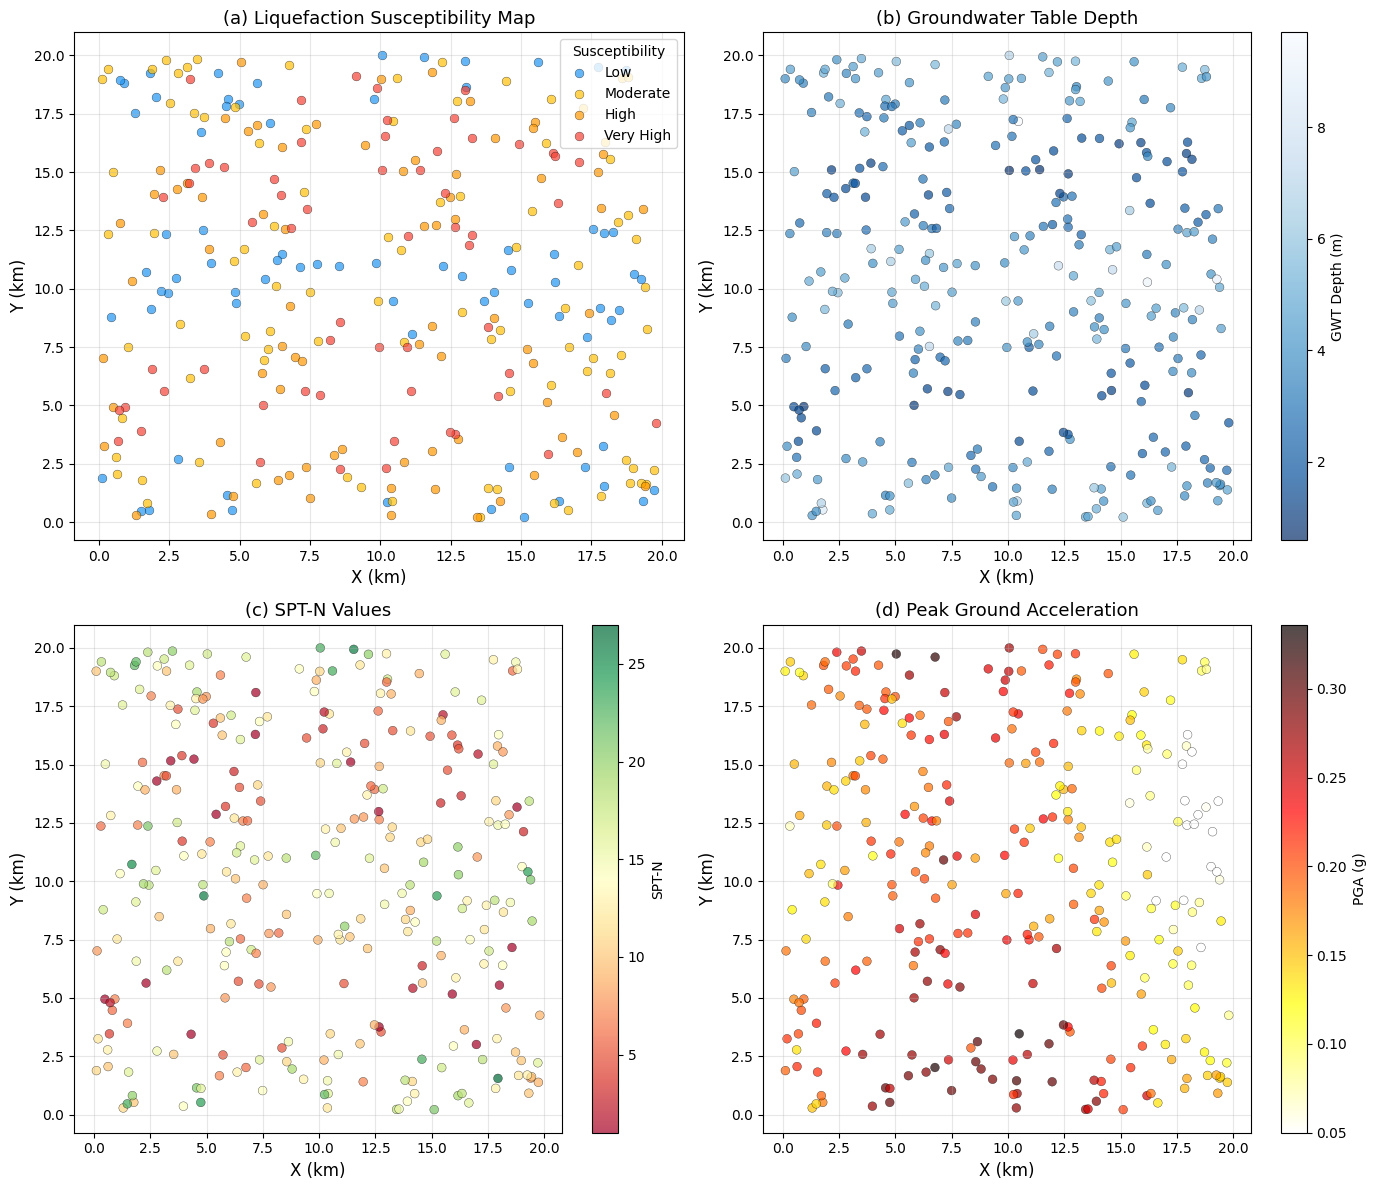

In [3]:
# ───── Part 3: Spatial Visualization ─────
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# (a) Susceptibility map
colors_map = {0: '#2196F3', 1: '#FFC107', 2: '#FF9800', 3: '#F44336'}
for cls, label in susc_labels.items():
    mask = df['susceptibility'] == cls
    axes[0, 0].scatter(df.loc[mask, 'x_km'], df.loc[mask, 'y_km'],
                       c=colors_map[cls], label=label, alpha=0.7, edgecolors='k', linewidth=0.3, s=40)
axes[0, 0].set_xlabel('X (km)', fontsize=12)
axes[0, 0].set_ylabel('Y (km)', fontsize=12)
axes[0, 0].set_title('(a) Liquefaction Susceptibility Map', fontsize=13)
axes[0, 0].legend(title='Susceptibility')
axes[0, 0].grid(True, alpha=0.3)

# (b) GWT depth map
sc = axes[0, 1].scatter(df['x_km'], df['y_km'], c=df['gwt_depth_m'],
                        cmap='Blues_r', alpha=0.7, edgecolors='k', linewidth=0.3, s=40)
plt.colorbar(sc, ax=axes[0, 1], label='GWT Depth (m)')
axes[0, 1].set_xlabel('X (km)', fontsize=12)
axes[0, 1].set_ylabel('Y (km)', fontsize=12)
axes[0, 1].set_title('(b) Groundwater Table Depth', fontsize=13)
axes[0, 1].grid(True, alpha=0.3)

# (c) SPT-N map
sc2 = axes[1, 0].scatter(df['x_km'], df['y_km'], c=df['spt_n'],
                         cmap='RdYlGn', alpha=0.7, edgecolors='k', linewidth=0.3, s=40)
plt.colorbar(sc2, ax=axes[1, 0], label='SPT-N')
axes[1, 0].set_xlabel('X (km)', fontsize=12)
axes[1, 0].set_ylabel('Y (km)', fontsize=12)
axes[1, 0].set_title('(c) SPT-N Values', fontsize=13)
axes[1, 0].grid(True, alpha=0.3)

# (d) PGA map
sc3 = axes[1, 1].scatter(df['x_km'], df['y_km'], c=df['pga_g'],
                         cmap='hot_r', alpha=0.7, edgecolors='k', linewidth=0.3, s=40)
plt.colorbar(sc3, ax=axes[1, 1], label='PGA (g)')
axes[1, 1].set_xlabel('X (km)', fontsize=12)
axes[1, 1].set_ylabel('Y (km)', fontsize=12)
axes[1, 1].set_title('(d) Peak Ground Acceleration', fontsize=13)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('spatial_maps.png', dpi=150, bbox_inches='tight')
plt.show()

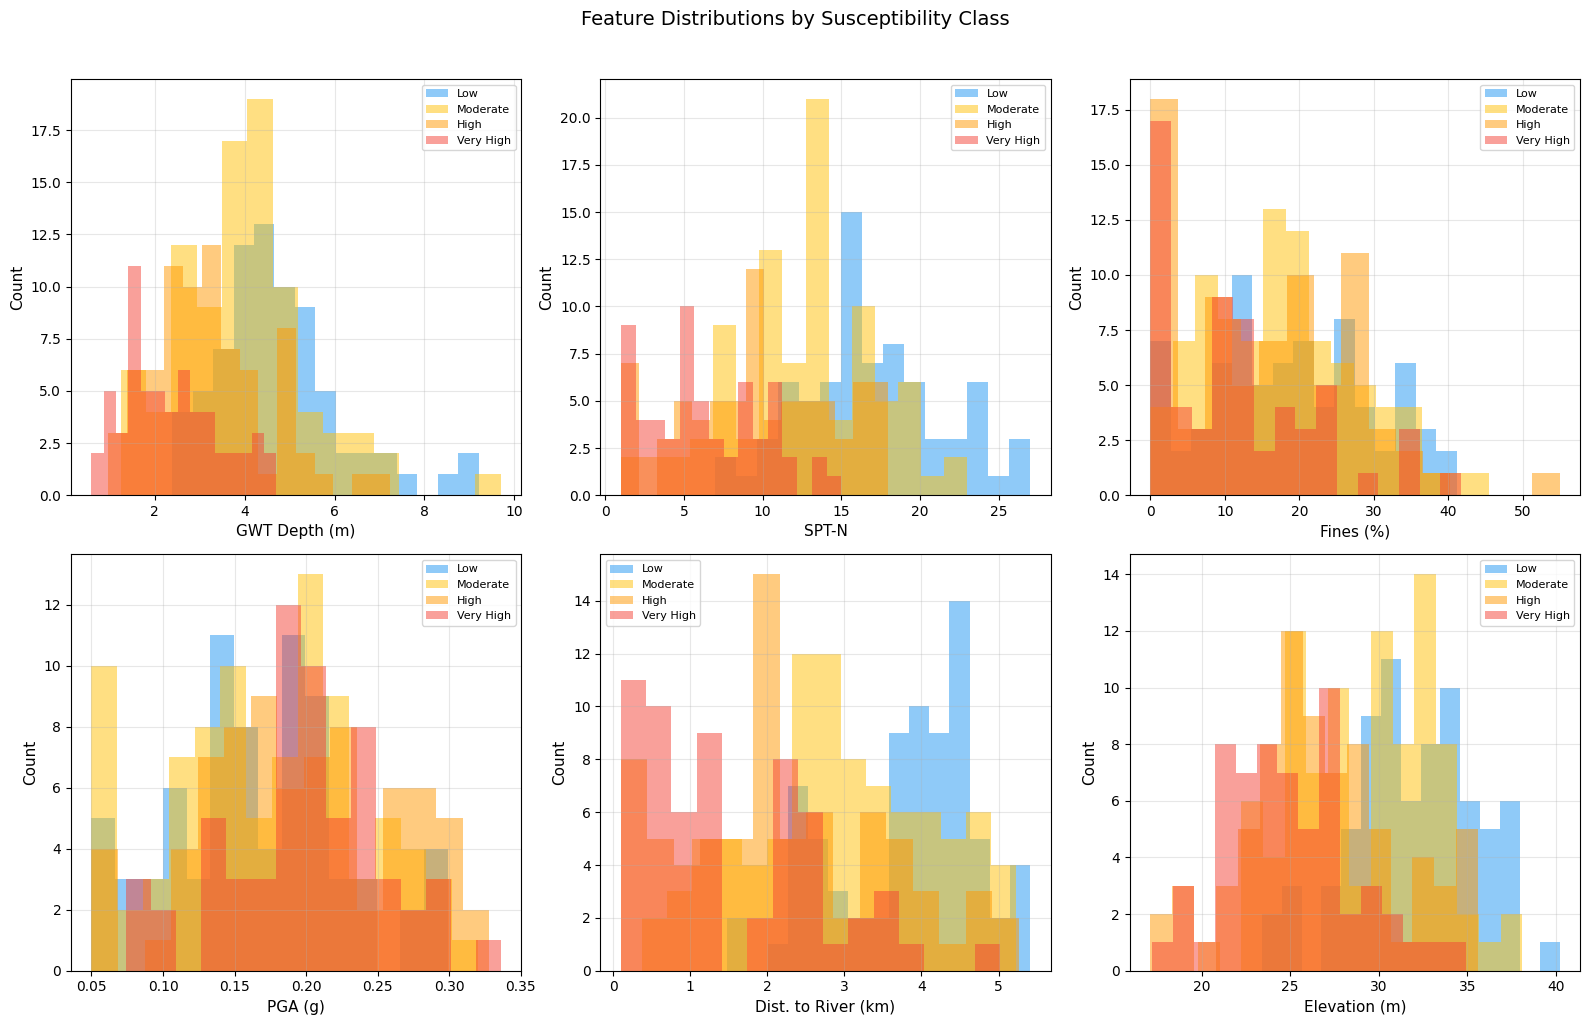

In [4]:
# ───── Part 4: Feature Distributions by Class ─────
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
feat_list = ['gwt_depth_m', 'spt_n', 'fines_pct', 'pga_g', 'dist_river_km', 'elevation_m']
feat_titles = ['GWT Depth (m)', 'SPT-N', 'Fines (%)', 'PGA (g)', 'Dist. to River (km)', 'Elevation (m)']

for idx, (feat, title) in enumerate(zip(feat_list, feat_titles)):
    ax = axes[idx // 3, idx % 3]
    for cls, label in susc_labels.items():
        mask = df['susceptibility'] == cls
        ax.hist(df.loc[mask, feat], bins=15, alpha=0.5, label=label, color=colors_map[cls])
    ax.set_xlabel(title, fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Feature Distributions by Susceptibility Class', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# ───── Part 5: Data Preparation ─────
features = ['elevation_m', 'gwt_depth_m', 'spt_n', 'fines_pct', 'pga_g', 'dist_river_km']
X = df[features].values
y = df['susceptibility'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f'Training: {X_train.shape[0]} samples')
print(f'Test:     {X_test.shape[0]} samples')
print(f'Number of classes: {len(np.unique(y))}')

Training: 240 samples
Test:     60 samples
Number of classes: 4


## Part 6: Deep Learning Model

We build a deep neural network with:
- 4 hidden layers (128, 64, 32, 16)
- Batch normalization and dropout
- Softmax output for 4-class classification
- Cross-entropy loss with class weights to handle imbalance

In [6]:
# ───── Part 6: Define DL Architecture ─────
class LiquefactionNet(nn.Module):
    def __init__(self, input_dim, n_classes):
        super(LiquefactionNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, n_classes)
        )

    def forward(self, x):
        return self.network(x)

n_classes = len(np.unique(y))
model = LiquefactionNet(input_dim=len(features), n_classes=n_classes)
print(model)
print(f'\nTotal parameters: {sum(p.numel() for p in model.parameters())}')

LiquefactionNet(
  (network): Sequential(
    (0): Linear(in_features=6, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=32, out_features=16, bias=True)
    (13): ReLU()
    (14): Linear(in_features=16, out_features=4, bias=True)
  )
)

Total parameters: 12276


In [7]:
# ───── Part 7: Train DL Model ─────
# Compute class weights for imbalanced data
class_counts = np.bincount(y_train, minlength=n_classes)
class_weights = 1.0 / np.maximum(class_counts, 1)
class_weights = class_weights / class_weights.sum() * len(class_counts)
weights_tensor = torch.FloatTensor(class_weights)

X_train_t = torch.FloatTensor(X_train_sc)
y_train_t = torch.LongTensor(y_train)
X_test_t = torch.FloatTensor(X_test_sc)
y_test_t = torch.LongTensor(y_test)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=15, factor=0.5)

epochs = 250
train_losses, val_losses, val_accs = [], [], []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    train_losses.append(epoch_loss / len(train_loader))

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_test_t)
        val_loss = criterion(val_outputs, y_test_t).item()
        val_losses.append(val_loss)
        _, predicted = torch.max(val_outputs, 1)
        val_acc = (predicted == y_test_t).float().mean().item()
        val_accs.append(val_acc)

    scheduler.step(val_loss)

    if (epoch + 1) % 50 == 0:
        print(f'Epoch [{epoch+1}/{epochs}] - Loss: {train_losses[-1]:.4f}, '
              f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.3f}')

print(f'\nTraining complete. Best val accuracy: {max(val_accs):.3f}')

Epoch [50/250] - Loss: 0.8969, Val Loss: 0.9772, Val Acc: 0.483


Epoch [100/250] - Loss: 0.8083, Val Loss: 1.0034, Val Acc: 0.450


Epoch [150/250] - Loss: 0.8366, Val Loss: 1.0081, Val Acc: 0.433


Epoch [200/250] - Loss: 0.7782, Val Loss: 0.9996, Val Acc: 0.467


Epoch [250/250] - Loss: 0.8601, Val Loss: 0.9975, Val Acc: 0.467

Training complete. Best val accuracy: 0.533


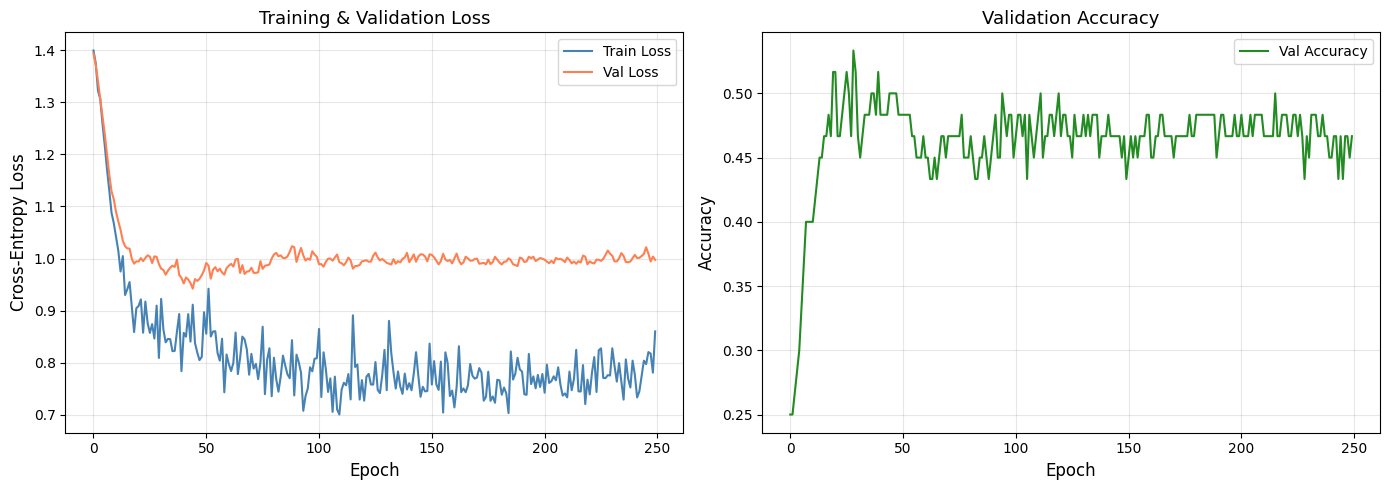

In [8]:
# ───── Part 8: Training History ─────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, label='Train Loss', color='steelblue', linewidth=1.5)
ax1.plot(val_losses, label='Val Loss', color='coral', linewidth=1.5)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Cross-Entropy Loss', fontsize=12)
ax1.set_title('Training & Validation Loss', fontsize=13)
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(val_accs, label='Val Accuracy', color='forestgreen', linewidth=1.5)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Accuracy', fontsize=12)
ax2.set_title('Validation Accuracy', fontsize=13)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# ───── Part 9: Model Evaluation ─────
model.eval()
with torch.no_grad():
    outputs = model(X_test_t)
    probs = torch.softmax(outputs, dim=1).numpy()
    _, y_pred = torch.max(outputs, 1)
    y_pred = y_pred.numpy()

print('=== Classification Report ===')
target_names = [susc_labels[i] for i in range(n_classes)]
print(classification_report(y_test, y_pred, target_names=target_names))
print(f'Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}')

=== Classification Report ===
              precision    recall  f1-score   support

         Low       0.50      0.73      0.59        15
    Moderate       0.38      0.33      0.35        18
        High       0.38      0.33      0.36        15
   Very High       0.67      0.50      0.57        12

    accuracy                           0.47        60
   macro avg       0.48      0.47      0.47        60
weighted avg       0.47      0.47      0.46        60

Overall Accuracy: 0.467


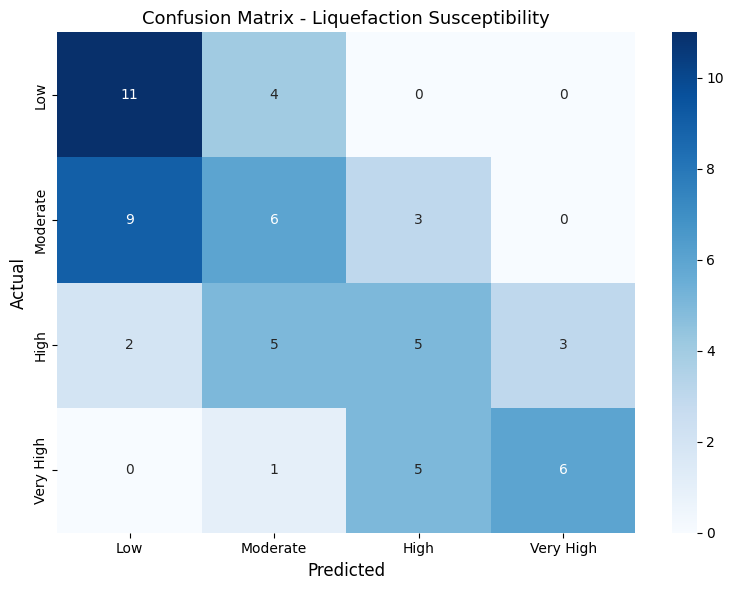

In [10]:
# ───── Part 10: Confusion Matrix ─────
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=target_names, yticklabels=target_names)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)
ax.set_title('Confusion Matrix - Liquefaction Susceptibility', fontsize=13)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

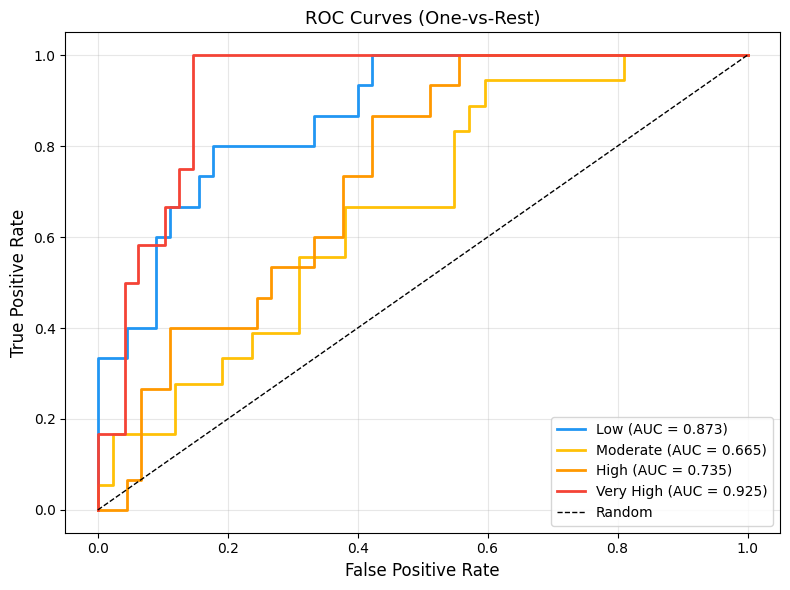

In [11]:
# ───── Part 11: ROC Curves (One-vs-Rest) ─────
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

fig, ax = plt.subplots(figsize=(8, 6))
colors_roc = ['#2196F3', '#FFC107', '#FF9800', '#F44336']

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors_roc[i], linewidth=2,
            label=f'{target_names[i]} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves (One-vs-Rest)', fontsize=13)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

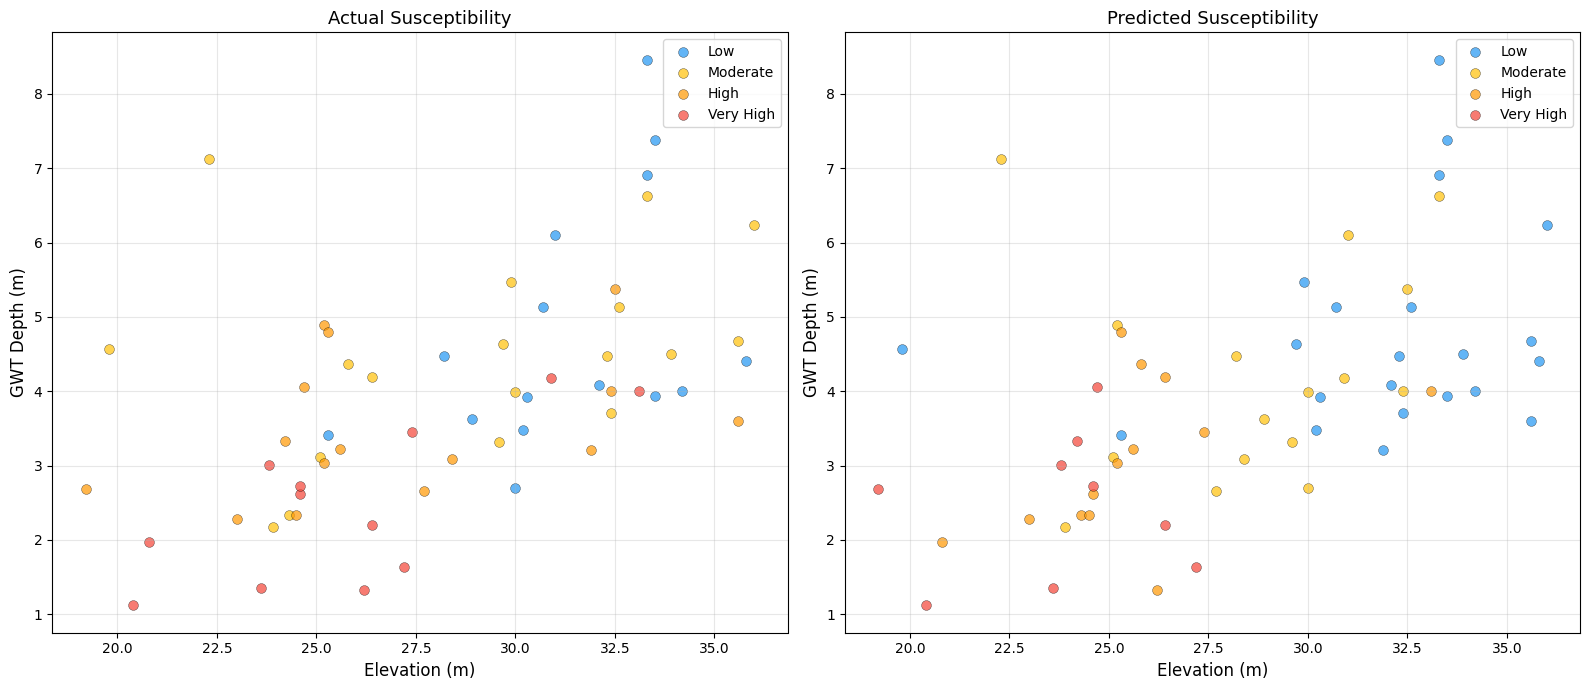

In [12]:
# ───── Part 12: Predicted Susceptibility Map (Test Set) ─────
# Get coordinates for test set
test_indices = df.index.isin(
    pd.Series(range(len(df))).sample(n=len(y_test), random_state=42).values
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Actual
for cls, label in susc_labels.items():
    mask = y_test == cls
    idx_mask = np.where(mask)[0]
    axes[0].scatter(X_test[idx_mask, 0], X_test[idx_mask, 1],  # elevation used as proxy
                    c=colors_map[cls], label=label, alpha=0.7, edgecolors='k',
                    linewidth=0.3, s=50)
axes[0].set_xlabel('Elevation (m)', fontsize=12)
axes[0].set_ylabel('GWT Depth (m)', fontsize=12)
axes[0].set_title('Actual Susceptibility', fontsize=13)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Predicted
for cls, label in susc_labels.items():
    mask = y_pred == cls
    idx_mask = np.where(mask)[0]
    axes[1].scatter(X_test[idx_mask, 0], X_test[idx_mask, 1],
                    c=colors_map[cls], label=label, alpha=0.7, edgecolors='k',
                    linewidth=0.3, s=50)
axes[1].set_xlabel('Elevation (m)', fontsize=12)
axes[1].set_ylabel('GWT Depth (m)', fontsize=12)
axes[1].set_title('Predicted Susceptibility', fontsize=13)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('predicted_map.png', dpi=150, bbox_inches='tight')
plt.show()

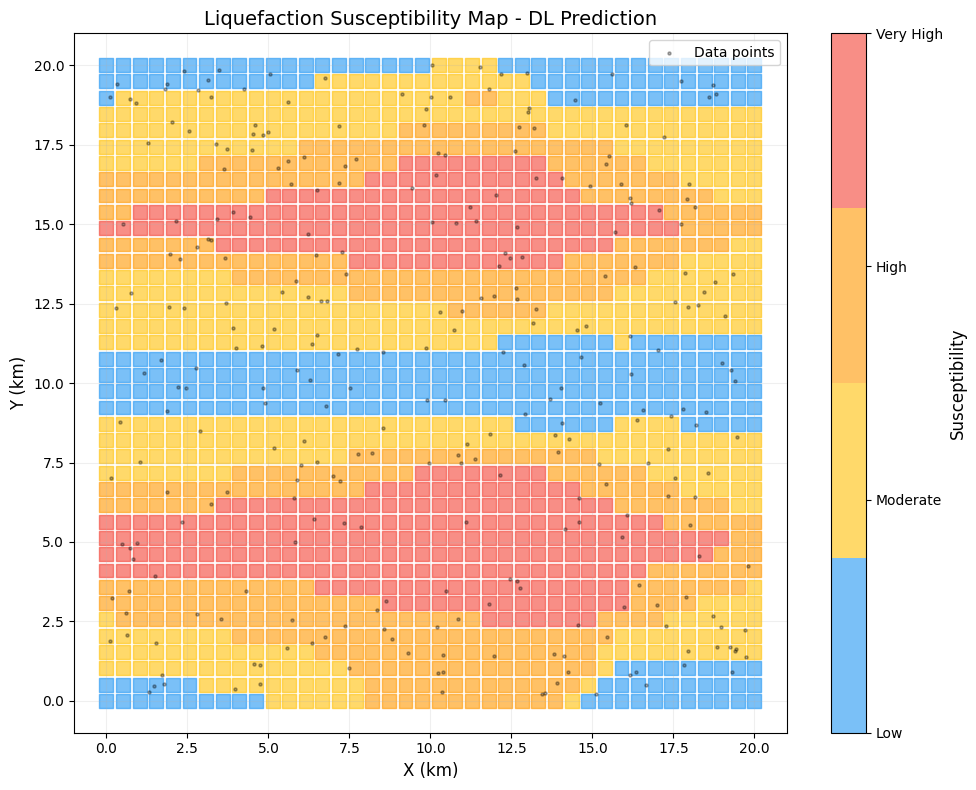

In [13]:
# ───── Part 13: Full Region Prediction Grid ─────
# Create a grid for the full region and predict susceptibility
grid_x = np.linspace(0, 20, 40)
grid_y = np.linspace(0, 20, 40)
xx, yy = np.meshgrid(grid_x, grid_y)
grid_points = np.column_stack([xx.ravel(), yy.ravel()])

# Compute features for grid points
g_dist_river = np.minimum(np.abs(grid_points[:, 1] - 5), np.abs(grid_points[:, 1] - 15))
g_elevation = 20 + 3 * g_dist_river
g_gwt = 0.5 + 0.8 * g_dist_river + 1.0  # mean of exponential
g_spt = (5 + 2.5 * g_dist_river).astype(int)
g_fines = 15 + 10 * np.sin(grid_points[:, 0] / 3)
g_pga = 0.15 + 0.1 * np.sin(grid_points[:, 0] / 5) + 0.05 * np.cos(grid_points[:, 1] / 4)

grid_features = np.column_stack([g_elevation, g_gwt, g_spt, g_fines, g_pga, g_dist_river])
grid_features_sc = scaler.transform(grid_features)

model.eval()
with torch.no_grad():
    grid_outputs = model(torch.FloatTensor(grid_features_sc))
    _, grid_pred = torch.max(grid_outputs, 1)
    grid_pred = grid_pred.numpy()

# Plot susceptibility map
fig, ax = plt.subplots(figsize=(10, 8))
from matplotlib.colors import ListedColormap
cmap_custom = ListedColormap(['#2196F3', '#FFC107', '#FF9800', '#F44336'])

im = ax.scatter(grid_points[:, 0], grid_points[:, 1], c=grid_pred,
                cmap=cmap_custom, s=100, marker='s', alpha=0.6, vmin=0, vmax=3)

# Overlay training data
ax.scatter(df['x_km'], df['y_km'], c='black', s=5, alpha=0.3, label='Data points')

cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(['Low', 'Moderate', 'High', 'Very High'])
cbar.set_label('Susceptibility', fontsize=12)
ax.set_xlabel('X (km)', fontsize=12)
ax.set_ylabel('Y (km)', fontsize=12)
ax.set_title('Liquefaction Susceptibility Map - DL Prediction', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('susceptibility_map_full.png', dpi=150, bbox_inches='tight')
plt.show()

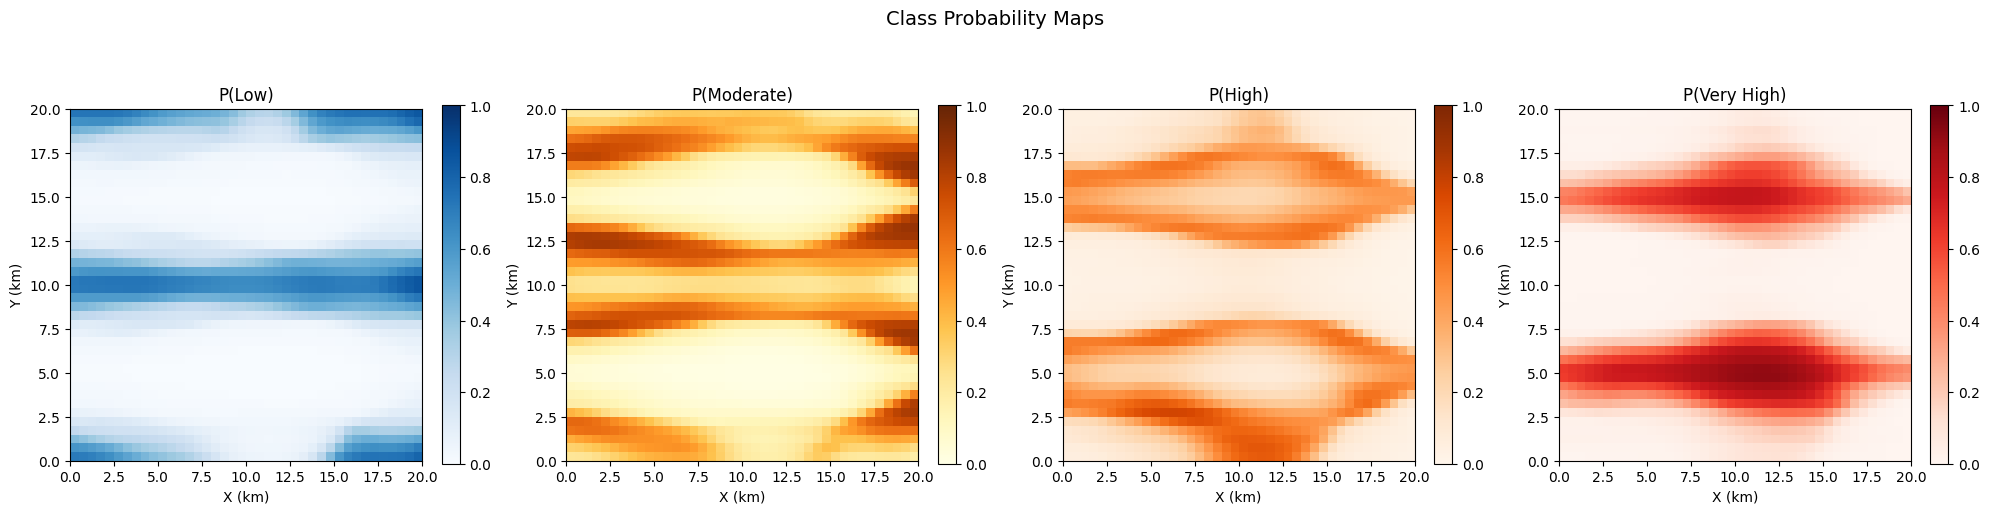

In [14]:
# ───── Part 14: Prediction Probability Map ─────
with torch.no_grad():
    grid_probs = torch.softmax(model(torch.FloatTensor(grid_features_sc)), dim=1).numpy()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, (label, cmap_name) in enumerate(zip(target_names,
                                           ['Blues', 'YlOrBr', 'Oranges', 'Reds'])):
    prob_grid = grid_probs[:, i].reshape(40, 40)
    im = axes[i].imshow(prob_grid, extent=[0, 20, 0, 20], origin='lower',
                        cmap=cmap_name, vmin=0, vmax=1, aspect='equal')
    axes[i].set_title(f'P({label})', fontsize=12)
    axes[i].set_xlabel('X (km)', fontsize=10)
    axes[i].set_ylabel('Y (km)', fontsize=10)
    plt.colorbar(im, ax=axes[i], fraction=0.046)

plt.suptitle('Class Probability Maps', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('probability_maps.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Takeaways

1. **Deep learning can effectively map liquefaction susceptibility** from geotechnical and spatial features, achieving multi-class classification with good accuracy.

2. **Groundwater depth and SPT-N are the strongest predictors** of liquefaction susceptibility, consistent with established geotechnical knowledge.

3. **Spatial patterns in susceptibility** are clearly captured, with higher risk zones near river channels where alluvial deposits and shallow water tables coexist.

4. **Class probability maps provide richer information** than hard classifications, allowing engineers to assess uncertainty in risk zones.

5. **Class weighting in the loss function** helps handle imbalanced susceptibility classes, a common challenge in hazard mapping.

## Next Steps

- Incorporate actual geological map data (lithology, age) as features
- Use graph neural networks for spatial dependencies
- Add temporal seismic hazard variation for dynamic susceptibility
- Validate with real liquefaction case histories
- Integrate with GIS for deployment in engineering practice